Text(0, 0.5, 'Normalized Temperature')

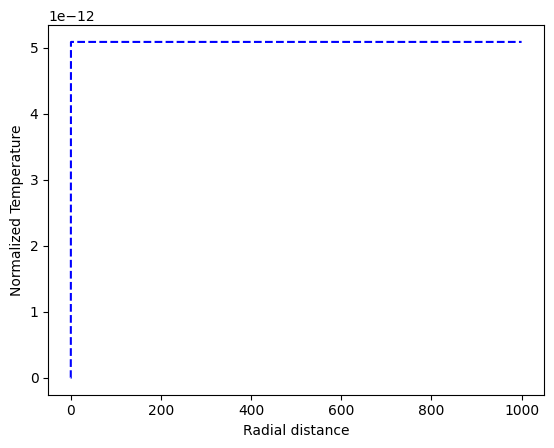

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pickle
from scipy.special import gamma, gammainc
pi = np.pi

df1 = pd.read_csv(r'advonin_csv_ptsuss_0106.csv')
df2 = pd.read_csv(r'advonin_csv_ptsuss_10009.csv')
df3 = pd.read_csv(r'advonin_csv_ptsuss_0014.csv')
df4 = pd.read_csv(r'advonin_csv_ptsuss_0028.csv')

x_coordinate = df1.iloc[:, 3]  # 4th column
r = x_coordinate

t1 = 1e6 #3600
t2 = 1e9 #86400
t3 = 2.592e6
t4 = 1.577e7

T0 = 443.15 #170 #331 #res temp
Ti = 433.15  #160 #294   # inj temp

temp_t1 = df1.iloc[:, 2] 
temp_t2 = df2.iloc[:, 2] 
temp_t3 = df3.iloc[:, 2] 
temp_t4 = df4.iloc[:, 2] 

temp_t1_bar = (temp_t1 - T0)/(Ti-T0)
temp_t2_bar = (temp_t2 - T0)/(Ti-T0)
temp_t3_bar = (temp_t3 - T0)/(Ti-T0)
temp_t4_bar = (temp_t4 - T0)/(Ti-T0)

# Example usage:

Q = 0.10 #0.606  # injection flow rate, m/s Replace with the desired value for Q

rho_g = 919 #516.48
C_g = 4185 # 2920.5 # specific heat capacity of gas
rhocg = rho_g * C_g

rho_1 = 2500 # 2350 
C_1 = 1000 #1100 # specific heat capacity of res
rho_2 = 2773.4 
C_2 = 829 # specific heat capacity of caprock
rhoc1 = rho_1 * C_1
rhoc2 = rho_2 * C_2
 

lambda2z = 1.600
lambdam = 20 # 3.083
ymin = 0
ymax = 5
h = 100 # ymax - ymin
z = 7.5 #7.5 #h/2 #zbar =0 

#advonin params
por = 0.20
rhom = (por*rho_g)+((1-por)*rho_1)
v = (Q*rhocg)/(4*pi*h*lambdam)
w = 2*r/h
t1 = 1e6 #secs
tow1 = (4*lambdam*t1)/(rhom*rhoc1*h**2)
tow2 = (4*lambdam*t2)/(rhom*rhoc1*h**2)
tow3 = (4*lambdam*t2)/(rhom*rhoc1*h**2)
tow4 = (4*lambdam*t2)/(rhom*rhoc1*h**2)

T1bar = (gammainc(v,w**2/(4*tow1)))/gamma(v)
T2bar = (gammainc(v,w**2/(4*tow2)))/gamma(v)
T3bar = (gammainc(v,w**2/(4*tow3)))/gamma(v)
T4bar = (gammainc(v,w**2/(4*tow4)))/gamma(v)


#plot Res Temp
plt.figure(1)
plt.plot(r, T1bar, label='t=1hr_analy',linestyle='dashed', color='blue')
#plt.plot(r, temp_t1_bar, label='t=1hr_num',linestyle='solid', color='blue')
#plt.plot(r, T2bar, label='t=1d_analy',linestyle='dashed', color='red')
#plt.plot(r, temp_t2_bar, label='t=1d_num',linestyle='solid', color='red')
#plt.plot(r, T3bar, label='t=1m_analy',linestyle='dashed', color='green')
#plt.plot(r, temp_t3_bar, label='t=1m_num',linestyle='solid', color='green')
#plt.plot(r, T4bar, label='t=6m_analy',linestyle='dashed', color='orange')
#plt.plot(r, temp_t4_bar, label='t=6m_num',linestyle='solid', color='orange')
#plt.legend(loc="upper right")
# convert y-axis to Logarithmic scale
#plt.xscale("log")
# Add labels and title
plt.xlabel('Radial distance')
plt.ylabel('Normalized Temperature')
#plt.title('z = 2.5 (mid reservoir)')
#plt.ylim(0,0.001)

